# Data Visualisation with SQL and Python

Part of my IBM Data Analyst Capstone project. In this notebook I load the Stack Overflow developer survey into a **SQLite database**, extract data with **SQL queries**, and visualise it with Matplotlib: histogram, box plot, scatter plot, bubble plot, pie chart, stacked bar chart, line chart and bar chart.

Two notes on the data:
- The survey records age and time spent as ranges, so I convert them to approximate midpoints for plotting.
- `CompTotal` is in each respondent's own currency, so totals and medians across respondents can't be compared. For compensation charts I use `ConvertedCompYearly`, which is converted to USD.

## 1. Set up the database

In [ ]:
!wget -q https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv

In [ ]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt

In [1]:
# Read the CSV file
df = pd.read_csv('survey-data.csv')

# Display the first few rows of the data
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


Write the survey data into a SQLite database as a table called `main`.

In [ ]:
import sqlite3

# Create a connection to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Write the dataframe to the SQLite database
df.to_sql('main', conn, if_exists='replace', index=False)


# Close the connection
conn.close()

Reconnect and check that the data was inserted.

In [2]:
# Reconnect to the SQLite database
conn = sqlite3.connect('survey-data.sqlite')

# Run a simple query to check the data
QUERY = "SELECT * FROM main LIMIT 5"
df_check = pd.read_sql_query(QUERY, conn)

# Display the results
print(df_check)

   ResponseId                      MainBranch                 Age  \
0           1  I am a developer by profession  Under 18 years old   
1           2  I am a developer by profession     35-44 years old   
2           3  I am a developer by profession     45-54 years old   
3           4           I am learning to code     18-24 years old   
4           5  I am a developer by profession     18-24 years old   

            Employment RemoteWork   Check  \
0  Employed, full-time     Remote  Apples   
1  Employed, full-time     Remote  Apples   
2  Employed, full-time     Remote  Apples   
3   Student, full-time        NaN  Apples   
4   Student, full-time        NaN  Apples   

                                    CodingActivities  \
0                                              Hobby   
1  Hobby;Contribute to open-source projects;Other...   
2  Hobby;Contribute to open-source projects;Other...   
3                                                NaN   
4                                 

## 2. SQL query examples
Count the rows in the table.

In [3]:
QUERY = """
SELECT COUNT(*) 
FROM main
"""
df = pd.read_sql_query(QUERY, conn)
df.head()

,COUNT(*)
0,65437


List the tables in the database.

In [ ]:
QUERY = """
SELECT name AS Table_Name FROM sqlite_master
WHERE type = 'table'
"""
pd.read_sql_query(QUERY, conn)

Group the respondents by age range.

In [ ]:
QUERY = """
SELECT Age, COUNT(*) AS Respondents
FROM main
GROUP BY Age
ORDER BY Respondents DESC
"""
pd.read_sql_query(QUERY, conn)

Describe the table schema.

In [4]:
table_name = 'main'

QUERY = """
SELECT sql FROM sqlite_master 
WHERE name= '{}'
""".format(table_name)

df = pd.read_sql_query(QUERY, conn)
print(df.iat[0,0])

CREATE TABLE "main" (
"ResponseId" INTEGER,
  "MainBranch" TEXT,
  "Age" TEXT,
  "Employment" TEXT,
  "RemoteWork" TEXT,
  "Check" TEXT,
  "CodingActivities" TEXT,
  "EdLevel" TEXT,
  "LearnCode" TEXT,
  "LearnCodeOnline" TEXT,
  "TechDoc" TEXT,
  "YearsCode" TEXT,
  "YearsCodePro" TEXT,
  "DevType" TEXT,
  "OrgSize" TEXT,
  "PurchaseInfluence" TEXT,
  "BuyNewTool" TEXT,
  "BuildvsBuy" TEXT,
  "TechEndorse" TEXT,
  "Country" TEXT,
  "Currency" TEXT,
  "CompTotal" REAL,
  "LanguageHaveWorkedWith" TEXT,
  "LanguageWantToWorkWith" TEXT,
  "LanguageAdmired" TEXT,
  "DatabaseHaveWorkedWith" TEXT,
  "DatabaseWantToWorkWith" TEXT,
  "DatabaseAdmired" TEXT,
  "PlatformHaveWorkedWith" TEXT,
  "PlatformWantToWorkWith" TEXT,
  "PlatformAdmired" TEXT,
  "WebframeHaveWorkedWith" TEXT,
  "WebframeWantToWorkWith" TEXT,
  "WebframeAdmired" TEXT,
  "EmbeddedHaveWorkedWith" TEXT,
  "EmbeddedWantToWorkWith" TEXT,
  "EmbeddedAdmired" TEXT,
  "MiscTechHaveWorkedWith" TEXT,
  "MiscTechWantToWorkWith" TEXT,


## 3. Distribution of data
**Histogram** of yearly compensation.

In [ ]:
df_comp = pd.read_sql_query(
    "SELECT ConvertedCompYearly FROM main WHERE ConvertedCompYearly IS NOT NULL", conn)
print("Respondents with reported compensation:", len(df_comp))

# Trim the top 5% so a few extreme values don't flatten the chart
upper = df_comp['ConvertedCompYearly'].quantile(0.95)
data = df_comp[df_comp['ConvertedCompYearly'] <= upper]['ConvertedCompYearly']
print("Rows plotted:", len(data))

plt.figure(figsize=(9, 5))
plt.hist(data, bins=40, color='steelblue', edgecolor='black')
plt.title('Distribution of Yearly Compensation (USD, bottom 95%)')
plt.xlabel('ConvertedCompYearly (USD)')
plt.ylabel('Number of respondents')
plt.show()

**Box plot** of age.

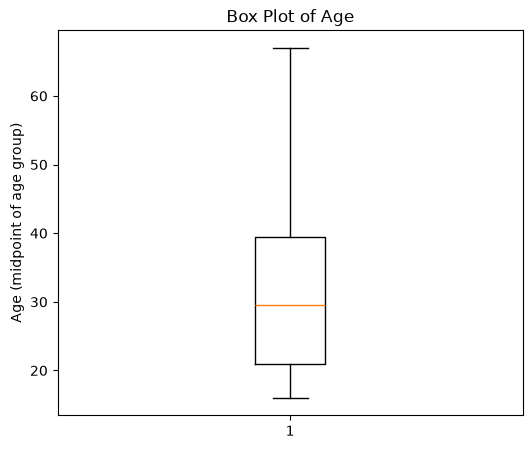

In [5]:
QUERY = "SELECT Age FROM main WHERE Age IS NOT NULL"
df_age = pd.read_sql_query(QUERY, conn)

# Age is stored as groups like '25-34 years old', so convert each group to a midpoint number
AGE_MID = {'Under 18 years old': 16, '18-24 years old': 21, '25-34 years old': 29.5,
           '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
           '65 years or older': 67}
num = pd.to_numeric(df_age['Age'], errors='coerce')
df_age['AgeNum'] = num.fillna(df_age['Age'].map(AGE_MID))

plt.figure(figsize=(6, 5))
plt.boxplot(df_age['AgeNum'].dropna())
plt.title('Box Plot of Age')
plt.ylabel('Age (midpoint of age group)')
plt.show()

## 4. Relationships in the data
**Scatter plot** of age and work experience. A small random jitter stops points from the same age group stacking on one vertical line.

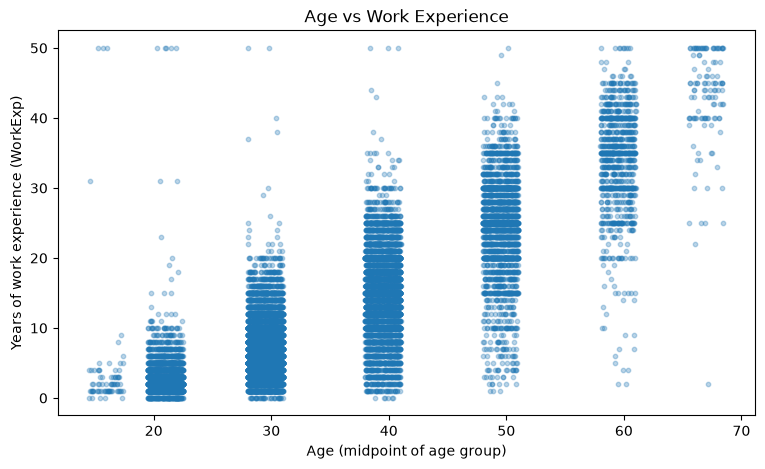

In [6]:
import random

QUERY = "SELECT Age, WorkExp FROM main WHERE Age IS NOT NULL AND WorkExp IS NOT NULL"
df_sc = pd.read_sql_query(QUERY, conn)

# Convert age groups like '25-34 years old' to a midpoint number
AGE_MID = {'Under 18 years old': 16, '18-24 years old': 21, '25-34 years old': 29.5,
           '35-44 years old': 39.5, '45-54 years old': 49.5, '55-64 years old': 59.5,
           '65 years or older': 67}
num = pd.to_numeric(df_sc['Age'], errors='coerce')
df_sc['AgeNum'] = num.fillna(df_sc['Age'].map(AGE_MID))
df_sc['WorkExp'] = pd.to_numeric(df_sc['WorkExp'], errors='coerce')
df_sc = df_sc.dropna(subset=['AgeNum', 'WorkExp'])

# Small jitter so points from the same age group don't stack on one vertical line
jitter = [random.uniform(-1.5, 1.5) for _ in range(len(df_sc))]

plt.figure(figsize=(9, 5))
plt.scatter(df_sc['AgeNum'] + jitter, df_sc['WorkExp'], alpha=0.3, s=10)
plt.title('Age vs Work Experience')
plt.xlabel('Age (midpoint of age group)')
plt.ylabel('Years of work experience (WorkExp)')
plt.show()

**Bubble plot** of time spent searching for answers against the number of frustrations listed, with bubble size showing average age.

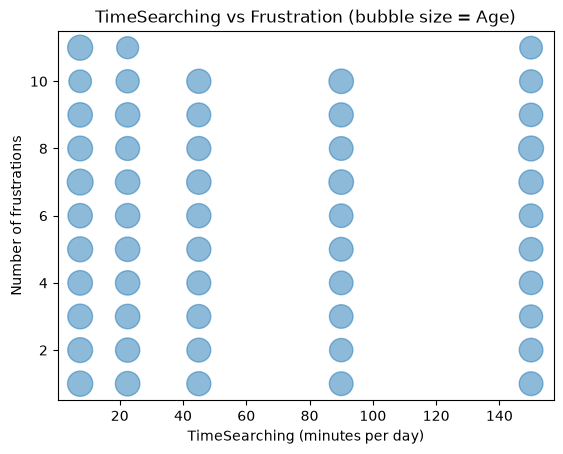

In [7]:
df = pd.read_sql_query("SELECT Age, TimeSearching, Frustration FROM main WHERE TimeSearching IS NOT NULL AND Frustration IS NOT NULL", conn)

time_map = {'Less than 15': 7.5, '15-30': 22.5, '30-60': 45, '60-120': 90, 'Over 120': 150}
def to_min(v):
    for k, m in time_map.items():
        if k in str(v): return m

df['Time'] = df['TimeSearching'].apply(to_min)
df['AgeNum'] = df['Age'].str.extract(r'(\d+)')[0].astype(float)
df['FrustCount'] = df['Frustration'].str.split(';').str.len()   # number of frustrations listed

g = df.groupby(['Time', 'FrustCount'], as_index=False)['AgeNum'].mean()

plt.scatter(g['Time'], g['FrustCount'], s=g['AgeNum'] * 10, alpha=0.5)
plt.title('TimeSearching vs Frustration (bubble size = Age)')
plt.xlabel('TimeSearching (minutes per day)')
plt.ylabel('Number of frustrations')
plt.show()

## 5. Composition of data
**Pie chart** of the top 5 databases respondents want to learn next year. The shares are among mentions of the top five, not among all respondents.

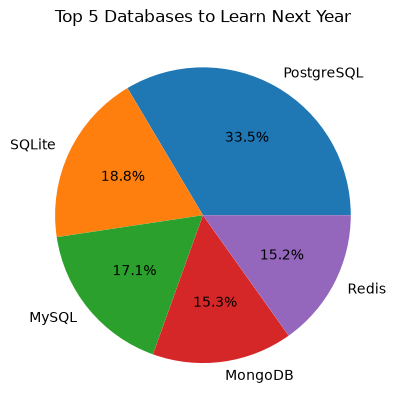

In [8]:
df = pd.read_sql_query("SELECT DatabaseWantToWorkWith FROM main WHERE DatabaseWantToWorkWith IS NOT NULL", conn)
top5 = df['DatabaseWantToWorkWith'].str.split(';').explode().value_counts().head(5)

plt.pie(top5.values, labels=top5.index, autopct='%1.1f%%')
plt.title('Top 5 Databases to Learn Next Year')
plt.show()

**Stacked bar chart** of median time spent searching and answering. The survey gives age ranges, so I use the two groups closest to 30 to 35 (25-34 and 35-44).

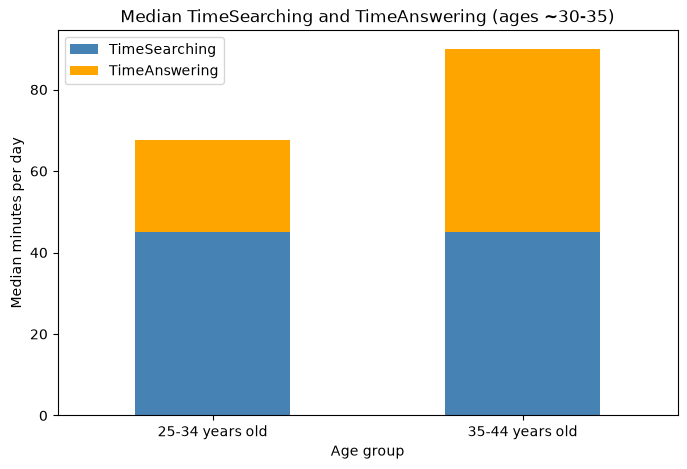

In [9]:
df = pd.read_sql_query("SELECT Age, TimeSearching, TimeAnswering FROM main WHERE TimeSearching IS NOT NULL AND TimeAnswering IS NOT NULL", conn)
df = df[df['Age'].isin(['25-34 years old', '35-44 years old'])]   # closest groups to 30-35

time_map = {'Less than 15': 7.5, '15-30': 22.5, '30-60': 45, '60-120': 90, 'Over 120': 150}
def to_min(v):
    for k, m in time_map.items():
        if k in str(v): return m

df['TimeSearching'] = df['TimeSearching'].apply(to_min)
df['TimeAnswering'] = df['TimeAnswering'].apply(to_min)

med = df.groupby('Age')[['TimeSearching', 'TimeAnswering']].median()

med.plot(kind='bar', stacked=True, figsize=(8, 5), color=['steelblue', 'orange'])
plt.title('Median TimeSearching and TimeAnswering (ages ~30-35)')
plt.xlabel('Age group')
plt.ylabel('Median minutes per day')
plt.xticks(rotation=0)
plt.show()

## 6. Comparison of data
**Line chart** of median compensation across the age groups from 45 to 64. With only two age groups this is a short line, but it shows the direction of the change.

In [ ]:
df = pd.read_sql_query(
    "SELECT Age, ConvertedCompYearly FROM main WHERE ConvertedCompYearly IS NOT NULL", conn)
df = df[df['Age'].isin(['45-54 years old', '55-64 years old'])]   # closest groups to 45-60

med = df.groupby('Age')['ConvertedCompYearly'].median()

plt.figure(figsize=(8, 5))
plt.plot(med.index, med.values, marker='o')
plt.title('Median Yearly Compensation (USD) for Ages 45 to 64')
plt.xlabel('Age group')
plt.ylabel('Median ConvertedCompYearly (USD)')
plt.grid(True)
plt.show()

**Horizontal bar chart** of respondents by main branch.

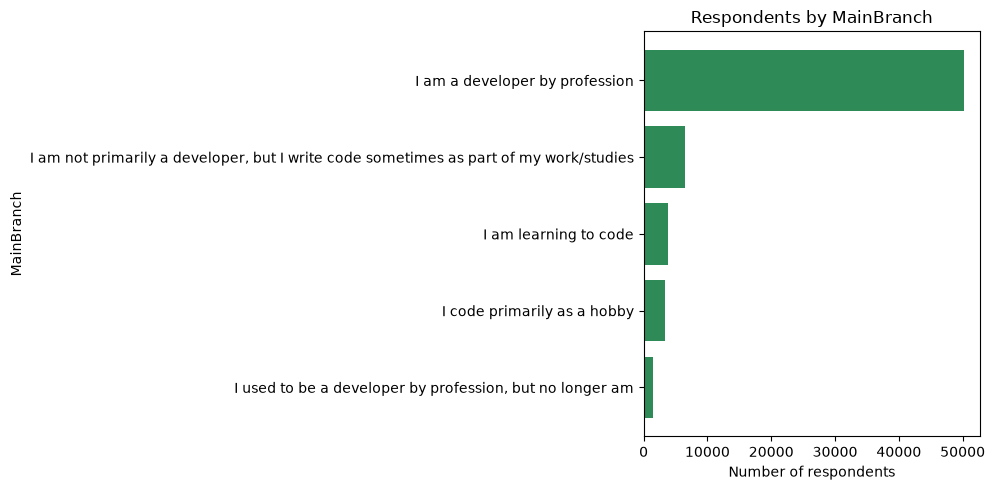

In [10]:
df = pd.read_sql_query("SELECT MainBranch, COUNT(*) AS count FROM main WHERE MainBranch IS NOT NULL GROUP BY MainBranch ORDER BY count", conn)

plt.figure(figsize=(10, 5))
plt.barh(df['MainBranch'], df['count'], color='seagreen')
plt.title('Respondents by MainBranch')
plt.xlabel('Number of respondents')
plt.ylabel('MainBranch')
plt.tight_layout()
plt.show()

Close the database connection.

In [ ]:
conn.close()